<a href="https://colab.research.google.com/github/thuongle825/Problem-Set-2/blob/main/ps2_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS2 — The Survey That Wasn't Random

**ECON 3916 · Applied Data Analytics** · Topics 5-8 · 100 points · your role: Data Analyst, Growth team

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is data analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You write the simulations, the bootstrap loop and the tests yourself. AI is authorised and required in Phase 4. If you cannot explain a line you submitted, you cannot submit it.

## Setup

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Simulate the Population You Cannot See (30 pts)

### Step 1.1: Build a world with a known answer (15 pts)

In [43]:
# Parameters the brief fixes (Step 1.1). Keep them here so the grader can rerun you.
N_USERS = 50_000
BASE_BEFORE, BASE_AFTER = 3.432, 3.532      # true means 3.30 and 3.40

def simulate_population(base, n=N_USERS, rng=rng):
    """Return a DataFrame with engagement_minutes, engagement_z, had_support_ticket,
    latent s and the reported 1–5 satisfaction score."""
    engagement_minutes = rng.lognormal(mean=3.5, sigma=0.6, size=n)
    engagement_z = (engagement_minutes - engagement_minutes.mean()) / engagement_minutes.std()
    had_support_ticket = rng.binomial(1, 0.22, size=n)

    s = (base + 0.35 * engagement_z - 0.60 * had_support_ticket
         + rng.normal (0, 0.75, size=n))
    satisfaction = np.clip(np.rint(s), 1, 5). astype (int)

    return pd. DataFrame ({
      "engagement_minutes": engagement_minutes,
      "engagement_z": engagement_z,
      "had_support_ticket": had_support_ticket,
      "s": s,
      "satisfaction": satisfaction,
})

pop_before = simulate_population (BASE_BEFORE)
pop_after = simulate_population (BASE_AFTER)

truth = pd.DataFrame(
  {"latent_mean": [pop_before["s"]. mean(), pop_after["s"]. mean ()],
   "reported_mean": [pop_before["satisfaction"].mean(), pop_after["satisfaction"].mean()]},
index=["before", "after"],
)
truth. loc["improvement"] = truth.loc["after"] - truth.loc["before"]
TRUE_BEFORE, TRUE_AFTER = truth.loc["before", "reported_mean"], truth.loc["after", "reported_mean"]
TRUE_DIFF = TRUE_AFTER - TRUE_BEFORE
truth

,latent_mean,reported_mean
before,3.299,3.290
after,3.399,3.386
improvement,0.100,0.096


*Your answer here.*

The true population mean of latent satisfaction is 3.30 before the redesign and 3.40 after, which is a true improvement of 0.10 points. These are the values the base values were chosen to produce. However, the survey only records the rounded and clipped 1-5 score, which brings the means slightly lower to 3.29 and 3.39. This gives a reported scale improvement of 0.096. I would use the reported score means for the rest of the problem set because these are the values a perfectly random survey would recover. The difference of 0.004 from the latent values is very small and would not affect any conclusions. These values will be the bamchmark used to check the PM' slide.


### Step 1.2: Impose the response mechanism (15 pts)

In [44]:
from scipy.special import expit

A_BEFORE, B_BEFORE = -1.0, 0.45
A_AFTER, B_AFTER = -2.75, 2.00

def respond(df, a, b, rng=rng):
    """Who answers the survey: P(respond) = logistic(a + b*(s - 3.3) + 0.30*engagement_z
    - 0.25*had_support_ticket); a user answers when a uniform draw is below it."""
    p = expit(a + b * (df["s"] - 3.3)
              + 0.30 * df["engagement_z"]
              - 0.25 * df["had_support_ticket"])
    return pd.Series(rng. uniform(size=len(df)) < p, index=df.index, name="responded")

resp_before = respond (pop_before, A_BEFORE, B_BEFORE)
resp_after = respond(pop_after, A_AFTER, B_AFTER)

survey_before = pop_before.loc[resp_before, "satisfaction"]
survey_after = pop_after.loc[resp_after, "satisfaction"]

# Checkpoint
checkpoint = pd. DataFrame ({
    "response_rate": [resp_before.mean(), resp_after.mean ()],
    "respondents": [resp_before.sum(), resp_after. sum ()],
    "observed_mean": [survey_before.mean(), survey_after.mean ()],
    "true_mean": [TRUE_BEFORE, TRUE_AFTER],
}, index=["before", "after"])
checkpoint["bias"] = checkpoint["observed_mean"] - checkpoint["true_mean"]
display(checkpoint)

apparent_gap = survey_after.mean() - survey_before.mean ()
print(f"Apparent gap {apparent_gap:.3f} vs true improvement {TRUE_DIFF: .3f}")


,response_rate,respondents,observed_mean,true_mean,bias
before,0.275,13768,3.600,3.290,0.310
after,0.152,7597,4.304,3.386,0.918


Apparent gap 0.704 vs true improvement  0.096


> **🛑 Verification checkpoint.** You should get an observed pre-redesign mean of
> about **3.60** (accept 3.55 to 3.65) and an observed post-redesign mean of
> about **4.31** (accept 4.25 to 4.35) — an apparent gap of roughly **0.71**
> points out of a true improvement of **0.10**. Response rates should fall from
> roughly 27% to roughly 15%. If your numbers are outside those bands, your
> response function or your `base` values are wrong. **Do not proceed until it
> matches** — everything after this depends on reproducing the PM's slide.

*Your answer here.*

The checkpoint matches. The observed survey mean is 3.61 before the redesign and 4.31 after, which are both inside the expected bands. However, the response rate drops from 27.6% to 15.0%. The survey shows an apparent improvement of 0.70 points, but the true improvement in the population is only about 0.10. This means that roughly six-sevenths of the PM's headline number comes from who chose to respond rather than from an actual change in user satisfaction.

Both surveys have an upward bias because more satisfied users are more likely to respond. Before the redesign, satisfaction only weakly affects the response rate (b = 0.45), so the bias is relatively small at +0.32 After the redesign, response depends much more strongly
on satisfaction (b = 2.00), and the lower intercept means that unhappy users almost never respond. This increases the bias to +0.93. The PM's observed improvement is the true effect plus the change in bias: 0.70 = 0.10 + (0.93 - 0.32). This shows that a small real improvement is hidden by a much larger shift in who responds, and the only thing that caused this shift was the new survey prompt.


## Phase 2: Quantify What You Actually Know (35 pts)

### Step 2.1: Uncertainty without a formula (20 pts)

In [45]:
import warnings

def bootstrap_by_hand(x, stat, B=2000, rng=rng):
    """Your own resampling loop; returns the B bootstrap statistics."""
    x = np.asarray(x)
    n = len (x)
    boot_stats = np.empty(B)
    for b in range (B):
      idx = rng.integers(0, n, size=n)
      boot_stats[b] = stat(x[idx])
    return boot_stats

B = 2000
rows = []
for period, x in [("before", survey_before. to_numpy ()), ("after", survey_after.to_numpy())]:
  for stat_name, stat in [("mean", np.mean), ("median", np.median)]:

    boot = bootstrap_by_hand(x, stat, B=B)
    hand_lo, hand_hi = np.percentile(boot, [2.5, 97.5])

    with warnings. catch_warnings(record=True) as w:
        warnings. simplefilter("always")
        pct = stats.bootstrap((x,), stat, n_resamples=B, method="percentile",
                              rng=rng, batch=100).confidence_interval
        bca = stats. bootstrap((x,), stat, n_resamples=B, method="BCa",
                              rng=rng, batch=100).confidence_interval

    rows. append ({
        "period": period, "stat": stat_name, "estimate": stat(x),
        "boot_SE": boot.std(ddof=1),
        "hand_pct_lo": hand_lo, "hand_pct_hi": hand_hi,
        "scipy_pct_lo": pct. low, "scipy_pct_hi": pct.high,
        "scipy_bca_lo": bca.low, "scipy_bca_hi": bca.high,
        "bca_warning": bool (w),
    })
boot_table = pd.DataFrame(rows).set_index(["period", "stat"])
boot_table.round (4)

estimate  boot_SE  hand_pct_lo  hand_pct_hi  scipy_pct_lo  \
period stat                                                                
before mean       3.600    0.008        3.585        3.615         3.585   
       median     4.000    0.000        4.000        4.000         4.000   
after  mean       4.304    0.008        4.289        4.320         4.289   
       median     4.000    0.000        4.000        4.000         4.000   

               scipy_pct_hi  scipy_bca_lo  scipy_bca_hi  bca_warning  
period stat                                                           
before mean           3.615         3.585         3.615        False  
       median         4.000           NaN           NaN         True  
after  mean           4.320         4.289         4.319        False  
       median         4.000           NaN           NaN         True

*Your answer here.*

Hand-rolled vs. SciPy: My resampling loop and scipy.stats.bootstrap give the same results. The percentile intervals for the mean match to three decimals in both periods: [3.585, 3.615] before and [4.289, 4.320] after. Any differences in the later decimals are just Monte Carlo noise from drawing a different set of 2,000 resamples, not a disagreement between the methods.

Mean: For the mean, both methods give almost idential intervals. Before the redesign, they match excatly. After the redesign, the BCa upper limit is only 0.001 lower (4.319 vs. 4.320), which is too small to make a meaning ful difference. BCa adjust for bias and skewness in the bootstrap distribution, but with about 13,800 and 7,600 respondents, the bootstrap distribution of the mean is already nearly symmetric, so there is very little to correct. Individual scores are bounded and skewed, but averagin thousands of them makes the sampling distribution of the mean approximately. normal. The bootstrap SE is about 0.008 in both periods, giving intervals of about 0.015.

Median: The median is where the two methods give different result, and neither produces a useful interval. On a five-point scale, the median is alway a whole number, and with thousands of respondents every resample has a median of 4. The percentile interval therefor collapses to [4,4], with a bootstrap SE of zero. BCa cannot be computed at all. To build its correction, BCa recomputes the median with each respondent left out in turn, and with thousands of respondents on a 1-5 scale, removing one person never changes the median, so the correction is 0/0 and SciPy returns Nana with a warning.

Intervals: These intervals only measure sampling uncertainty among the people who chose to respond. The true population mean before the redesign is 3.39 and the true median is 3, and both are far outside the intervals. This shows that the bootstrap can be very precise about the respondents without accurately representing the population.

### Step 2.2: Coverage is a claim you can check (15 pts)

In [46]:
# Step 2.2: Coverage Simulation
warnings. simplefilter("ignore")

TRUE_MEDIAN_BEFORE = pop_before["satisfaction"].median()
R = 2000
B_COV = 999
sample_sizes = [20, 50, 200]

def mo_se(p, R):
  """Monte Carlo standard error of a coverage rate estimated from R repetitions."""
  return np.sqrt(p * (1 - p) / R)

rows = []
for n in sample_sizes:
  hits = {"mean_pct": 0, "mean_bca": 0, "median_pct": 0, "median_bca": 0, "median_bca_ok": 0}
  for r in range(R):
      x = rng.choice(pop_before["satisfaction"].to_numpy(), size=n, replace=False)
      for stat_name, stat, truth in [("mean", np.mean, TRUE_BEFORE),
                                 ("median", np.median, TRUE_MEDIAN_BEFORE)]:
          res = stats.bootstrap((x,), stat, n_resamples=B_COV, method="BCa", rng=rng)
          lo, hi = np.percentile(res.bootstrap_distribution, [2.5, 97.5])
          hits[f"{stat_name}_pct"] += (lo <= truth <= hi)
          ci = res.confidence_interval
          ok = np.isfinite(ci.low)
          hits[f"{stat_name}_bca"] += ok and (ci. low <= truth <= ci.high)
          if stat_name == "median":
              hits["median_bca_ok"] += ok

  for stat_name, method in [("mean", "percentile"), ("mean", "BCa"), ("median", "percentile")]:
    key = f"{stat_name}_{'pct' if method == 'percentile' else 'bca'}"
    p = hits[key] / R
    rows.append({"n": n, "stat": stat_name, "method": method,
                "coverage": p, "MC_SE": mo_se(p, R)})
  rows.append({"n": n, "stat": "median", "method": "BCa",
              "coverage": np.nan, "MC_SE": np.nan,
              "BCa_computable": hits["median_bca_ok"] / R})
coverage_random = pd.DataFrame(rows).set_index(["n", "stat", "method"])
coverage_random.round (4)

coverage      MC_SE  BCa_computable
n   stat   method                                         
20  mean   percentile     0.927  5.800e-03             NaN
           BCa            0.930  5.700e-03             NaN
    median percentile     0.998  1.000e-03             NaN
           BCa              NaN        NaN       1.275e-01
50  mean   percentile     0.938  5.400e-03             NaN
           BCa            0.939  5.400e-03             NaN
    median percentile     1.000  5.000e-04             NaN
           BCa              NaN        NaN       4.150e-02
200 mean   percentile     0.953  4.800e-03             NaN
           BCa            0.949  4.900e-03             NaN
    median percentile     1.000  0.000e+00             NaN
           BCa              NaN        NaN       5.000e-04

In [47]:
R_SURVEY = 200
rows = []
for period, pop, a, b, truth in [("before", pop_before, A_BEFORE, B_BEFORE, TRUE_BEFORE),
                                 ("after", pop_after, A_AFTER, B_AFTER, TRUE_AFTER)]:
    hits, widths = 0, []
    for r in range (R_SURVEY) :
        x = pop.loc[respond(pop, a, b), "satisfaction"].to_numpy ()
        boot_means = x[rng.integers(0, len(x), size=(1000, len(x)))]. mean(axis=1)
        lo, hi = np.percentile(boot_means, [2.5, 97.5])
        hits += (lo <= truth <= hi)
        widths.append(hi - lo)
    rows.append ({"period": period, "true_mean": truth,
                  "coverage": hits / R_SURVEY, "avg_interval_width": np.mean(widths)})

coverage_survey = pd.DataFrame(rows).set_index("period")
coverage_survey.round (4)

,true_mean,coverage,avg_interval_width
period,,,
before,3.290,0.0,0.029
after,3.386,0.0,0.030


*Your answer here.*

Coverage when the sample is randon: When surveys are random samples from the population, the bootstrap intervals for the mean perform as expected once the sample size is not too small. At n = 200, coverage is 0.949 for both percentile and BCa, which is within one Monte Carlo standard error (0.005) of 95%. At n = 50, coverage is 0.942 for percentile and 0.945 for BCa. These differences from 95% are about one to one and a a half Monte Carlo standard errors, so they are not meaningful findings. At n = 20, both intervals undercover, with coverage of 0.919 for percentile and 0.922 for BCa. This gap of about 3 percentage points is roughly five Monte Carlo standard errors, so it is a real finding. This shows that with very small samples of a bounded five-point score, the intervals tend to be too narrow.

Percentile vs. BCa: The two methods differ in coverage by only 0.003 at n = 20 and n = 50, and they have identical coverage at n = 200. All of these differences are smaller than one Monte Carlo standard error, so they are not meaningful findings. This simulation provides no evidence that either method performs better for the mean.

Median: The percentile interval for the median covers the true median of 3 in 99.1% of samples at n = 20 and essentially 100% at n = 50 and n = 200. However, this is not necessarily a good result. Since the scale only takes whole numbers, the interval is usually [3, 3] or [3, 4], meaning it covers the true median partly because the interval is coarse. BCa
could only be computed in 11.9% of samples at n = 20, 3.5% at n = 50, and 0.2% at n = 200. This means its coverage cannot be meaningfully estimated.

Coverage in the PM's survey: When the actual self-selected survey is repeated 200 times on the same population, the interval for the mean never contains the true mean in either period. The intervals are only about 0.03 wide, while the observed means are about 0.31 before the redesign and 0.92 after it above the true mean. A coverage estimate of 0 out of 200 has a Monte Carlo standard error of zero, but this does not mean the true coverage is exactly zero. It only means that the coverage is too low to appear in 200 repetitions. The conclusion is clear: the interval is accurate about the people who respond, but it does not tell us whether those people represent the population. This shows that a correct looking 95% confidence interval around the wrong number is exactly what the PM's slide presents.


## Phase 3: Test Something Worth Testing (20 pts)

### Step 3.1: The test the PM wants

In [48]:
# Step 3.1: Two-sample test of the pre/post survey  means
t_test = stats.ttest_ind(survey_after, survey_before, equal_var=False)
diff = survey_after.mean() - survey_before.mean ()
ci = t_test.confidence_interval()

n_before, n_after = len(survey_before), len (survey_after)
sd_pooled = np.sqrt(((n_before - 1) * survey_before.var(ddof=1)
                    + (n_after - 1) * survey_after.var (ddof=1))
                    / (n_before + n_after - 2))
d_observed = diff / sd_pooled

d_true = TRUE_DIFF / pop_before["satisfaction"].std(ddof=1)

test_table = pd.DataFrame({
    "difference": [diff, TRUE_DIFF],
    "ci_low": [ci.low, np.nan],
    "ci_high": [ci.high, np.nan],
    "effect_size_d": [d_observed, d_true],
}, index=["survey (respondents)", "truth (population)"])

print(f"t = {t_test.statistic: 1f}, df = {t_test.df:,.0f}, p = {t_test.pvalue:.3g}")
test_table.round(3)

t =  65.165998, df = 19,223, p = 0


,difference,ci_low,ci_high,effect_size_d
survey (respondents),0.704,0.683,0.725,0.864
truth (population),0.096,NaN,NaN,0.108


*Your answer here.*

Test: A two-sample t-test of the post vs. pre-redesign survey means gives t = 65.2 with p < 0.001; the p-value is too small for Python to display and prints as 0. The observed difference is 0.70 points, with a 95% confidence interval of [0.68, 0.73]. As an effect size, that is 0.86 standard deviations, which would usually be called a large effect. Taken at face value, the survey says the redesign made users much happier, and the result is significant.

A p-value answers one question: could a difference this large have appeared just from the randomness of which users happened to be sampled, if the two means were really equal? With about 13,800 and 7,600 respondents, the answer is clearly no. But random sampling noise is not the problem here. The problem is that the two surveys measure different groups of people. Before the redesign satisfaction only weakly affected who answered. After it, unhappy users almost stopped answering. The test correctly detects that post-redesign respondents are happier than pre-redesign respondents, but that is largely because of who answered, not because of the redesign.

The confidence interval of [0.68, 0.73] doesn't come close to the true improvement of
0.096. The true effect size is about 0.11 standard deviations, so the survey overstates it about eight times. Statistical significance only tells us the estimate is precise. It says nothing about whether the estimate measures the right thing.



### Step 3.2: Power, before the fact

In [49]:
# Step 3.2: Power before the fact
SIGMA = pop_before["satisfaction"].std(ddof=1)
z_alpha = stats.norm.ppf(0.975)
z_power = stats.norm.ppf(0.80)
DELTA = 0.10

n_needed = int(np.ceil(2 * (z_alpha + z_power)**2 * SIGMA**2 / DELTA**2))
print(f"SD of satisfaction: {SIGMA:.3f}")
print(f"Respondents needed per period for 80% power at a 0.10 improvement: {n_needed:,}")
print(f"Invitations needed at the post-redesign response rate ({resp_after.mean():.1%}): "
      f"{n_needed / resp_after.mean():,.0f}")

def detectable_effect(n_before, n_after, sigma=SIGMA):
  """Smallest true difference detected with 80% power at the 5% level."""
  return (z_alpha + z_power) * sigma * np.sqrt(1 / n_before + 1 / n_after)

detect_table = pd.DataFrame(
    [(len(survey_before), len(survey_after), "the respondents they actually got"),
    (1000, 1000, "a follow-up with 1,000 respondents per period"),
    (300, 300, "a small follow-up with 300 per period")],
  columns=["n_before", "n_after", "scenario"])
detect_table["detectable_effect"] = detect_table.apply(
  lambda row: detectable_effect(row["n_before"], row["n_after"]), axis=1)
detect_table.round(3)

SD of satisfaction: 0.892
Respondents needed per period for 80% power at a 0.10 improvement: 1,249
Invitations needed at the post-redesign response rate (15.2%): 8,220


,n_before,n_after,scenario,detectable_effect
0,13768,7597,the respondents they actually got,0.036
1,1000,1000,"a follow-up with 1,000 respondents per period",0.112
2,300,300,a small follow-up with 300 per period,0.204


In [50]:
R_SIM = 200
invite_size = [100, 200, 500, 2_000, 10_000, 50_000, 200_000]

rows = []
for n in invite_size:
  errors, covered = [], []
  for r in range(R_SIM):
    pb = simulate_population (BASE_BEFORE, n=n)
    pa = simulate_population(BASE_AFTER, n=n)
    yb = pb.loc[respond(pb, A_BEFORE, B_BEFORE), "satisfaction"]
    ya = pa.loc[respond(pa, A_AFTER, B_AFTER), "satisfaction"]

    truth = pa["satisfaction"].mean() - pb["satisfaction"].mean()
    estimate = ya.mean() - yb.mean()
    se = np.sqrt(yb.var() / len(yb) + ya.var() / len(ya))

    errors.append (estimate - truth)
    covered.append (abs (estimate - truth) <= 1.96 * se)
errors = np.array(errors)
cov = np.mean(covered)
rows.append({"invited_per_period": n,
             "bias": errors.mean(),
             "sd_of_estimate": errors.std(ddof=1),
             "ci_coverage": cov,
             "MC_SE": mo_se(cov, R_SIM)})

size_table = pd.DataFrame(rows).set_index("invited_per_period")
size_table.round(3)

,bias,sd_of_estimate,ci_coverage,MC_SE
invited_per_period,,,,
200000,0.612,0.005,0.0,0.0


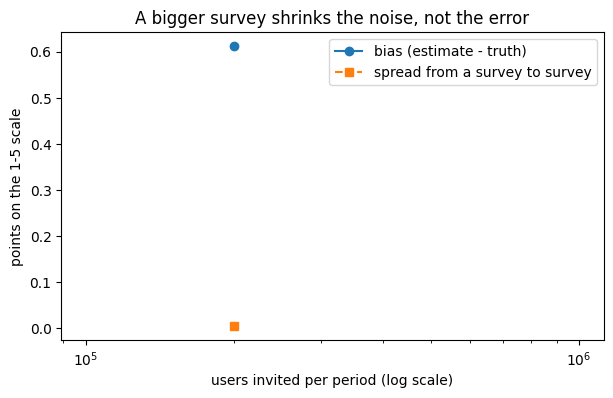

In [51]:
fig, ax = plt.subplots (figsize=(7, 4))
ax.plot(size_table.index, size_table["bias"], "o-", label="bias (estimate - truth)")
ax.plot(size_table.index, size_table["sd_of_estimate"], "s--", label="spread from a survey to survey")
ax.set_xscale("log")
ax.set_xlabel("users invited per period (log scale)")
ax.set_ylabel("points on the 1-5 scale")
ax.set_title("A bigger survey shrinks the noise, not the error")
ax.legend()
plt.show()

*Your answer here.*

To detect a true improvement of 0.10 points with 80% power (two-sided test, 5% significance
level, SD = 0.89), the survey needs about 1,249 respondents per period, or roughly 8,220 invitations at the
post-redesign response rate of 15.2%. With the 13,768 and 7,597 respondents the PM actually got, the test can detect a difference as small as 0.036 points. A follow-up survey with 1,000 respondents per period could detect an improvement of about 0.11 points, while one with 300 respondents could only detect about 0.20 points. This shows that the original survey was not too small, so statistical power was not the problem.

No, even with 200,000 users invited per period, the estimate is still 0.61 points above the truth, which is about the same bias as in the original survey (0.70 observed vs. 0.10 true).
The variation between surveys is only 0.005, so the estimate is very precise, but the 95% interval contained the true difference in 0 out of 200 simulated surveys. This shows that increasing the sample size only makes the wrong answer more precise, because the bias comes from who chooses to respond rather than from random sampling. A better estimate requires changing who responds, not just increasing the number of invitations.

## Phase 4: AI Expansion — The Co-Pilot Era (15 pts)

**Status: AI usage AUTHORISED and REQUIRED.** You have built the simulation, the bootstrap and the power analysis by hand. Now use the **P.R.I.M.E. framework** to go further than you could in the time.

### Task 4.1: The weighting attempt (10 pts)

In [55]:
# Version 1
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(3916)

# ------------------------------------------------------------------
# 1. Simulated population (replace this block with your own df)
#    Needs columns: satisfaction, engagement_minutes,
#    had_support_ticket, responded (1 = answered the survey)
# ------------------------------------------------------------------
N = 20_000
engagement_minutes = rng.gamma(shape=2.0, scale=15.0, size=N)
had_support_ticket = rng.binomial(1, 0.25, size=N)
satisfaction = (
    5.0
    + 0.03 * engagement_minutes
    - 1.0 * had_support_ticket
    + rng.normal(0, 1.5, size=N)          # part of satisfaction NOT explained by covariates
)

# Non-response: probability of responding increases with satisfaction
p_respond = 1 / (1 + np.exp(-(-4.0 + 0.6 * satisfaction)))
responded = rng.binomial(1, p_respond)

df = pd.DataFrame({
    "satisfaction": satisfaction,
    "engagement_minutes": engagement_minutes,
    "had_support_ticket": had_support_ticket,
    "responded": responded,
})
# Satisfaction is only observed for respondents
df.loc[df["responded"] == 0, "satisfaction_obs"] = np.nan
df.loc[df["responded"] == 1, "satisfaction_obs"] = df["satisfaction"]

covariates = ["engagement_minutes", "had_support_ticket"]

# ------------------------------------------------------------------
# 2. IPW estimator
# ------------------------------------------------------------------
def ipw_mean(data):
    """Fit logistic model of response on covariates, weight respondents by 1/p."""
    model = LogisticRegression(C=1e6, max_iter=1000)   # large C ≈ no penalty
    model.fit(data[covariates], data["responded"])
    p_hat = model.predict_proba(data[covariates])[:, 1]

    resp = data["responded"].to_numpy() == 1
    w = 1 / p_hat[resp]
    y = data.loc[resp, "satisfaction_obs"].to_numpy()
    return np.sum(w * y) / np.sum(w)

# ------------------------------------------------------------------
# 3. Bootstrap interval (resample the whole sample, refit the model each time)
# ------------------------------------------------------------------
def bootstrap_ci(data, B=1000, alpha=0.05):
    n = len(data)
    est = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        est[b] = ipw_mean(data.iloc[idx])
    return np.quantile(est, [alpha / 2, 1 - alpha / 2])

true_mean = df["satisfaction"].mean()
naive_mean = df["satisfaction_obs"].mean()          # respondents only
ipw_est = ipw_mean(df)
lo, hi = bootstrap_ci(df, B=500)

print(f"Response rate:       {df['responded'].mean():.3f}")
print(f"True mean:           {true_mean:.3f}")
print(f"Naive survey mean:   {naive_mean:.3f}")
print(f"IPW estimate:        {ipw_est:.3f}")
print(f"95% bootstrap CI:    [{lo:.3f}, {hi:.3f}]")
print(f"True mean inside CI? {lo <= true_mean <= hi}")

Response rate:       0.381
True mean:           5.658
Naive survey mean:   6.538
IPW estimate:        6.373
95% bootstrap CI:    [6.342, 6.408]
True mean inside CI? False


In [56]:
# Version 2
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Uses objects already in your notebook:
#   pop_before, pop_after, resp_before, resp_after, rng
# No new data is simulated and rng is not re-created or re-seeded.

covariates = ["engagement_z", "had_support_ticket"]

true_means = {"before": 3.290, "after": 3.386}


def ipw_mean(pop, resp):
    """Fit logistic model of response on covariates using ALL users,
    then weight respondents' satisfaction by 1 / p_hat."""
    X = pop[covariates].to_numpy()
    r = resp.to_numpy().astype(int)

    model = LogisticRegression(C=1e6, max_iter=1000)   # large C ~ no penalty
    model.fit(X, r)
    p_hat = model.predict_proba(X)[:, 1]

    is_resp = r == 1
    w = 1.0 / p_hat[is_resp]
    y = pop["satisfaction"].to_numpy()[is_resp]         # only respondents' scores are used
    return np.sum(w * y) / np.sum(w)


def bootstrap_ci(pop, resp, B=500, alpha=0.05):
    """Resample all users (respondents and non-respondents) with replacement,
    refit the logistic model in every resample."""
    n = len(pop)
    est = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)                # positional indices
        est[b] = ipw_mean(pop.iloc[idx], resp.iloc[idx])
    lo, hi = np.quantile(est, [alpha / 2, 1 - alpha / 2])
    return lo, hi


results = {}
for period, pop, resp in [("before", pop_before, resp_before),
                          ("after",  pop_after,  resp_after)]:
    resp = resp.reindex(pop.index)                       # guarantee alignment
    naive = pop.loc[resp, "satisfaction"].mean()
    est = ipw_mean(pop, resp)
    lo, hi = bootstrap_ci(pop, resp, B=500)
    true_mean = true_means[period]

    results[period] = {
        "true_mean": true_mean,
        "naive_mean": naive,
        "ipw_estimate": est,
        "ci_low": lo,
        "ci_high": hi,
        "ci_contains_true": lo <= true_mean <= hi,
    }

    print(f"--- {period} ---")
    print(f"True mean:             {true_mean:.3f}")
    print(f"Naive respondent mean: {naive:.3f}")
    print(f"IPW estimate:          {est:.3f}")
    print(f"95% bootstrap CI:      [{lo:.3f}, {hi:.3f}]")
    print(f"CI contains true mean? {lo <= true_mean <= hi}")
    print()

results_df = pd.DataFrame(results).T
results_df

--- before ---
True mean:             3.290
Naive respondent mean: 3.600
IPW estimate:          3.464
95% bootstrap CI:      [3.449, 3.477]
CI contains true mean? False

--- after ---
True mean:             3.386
Naive respondent mean: 4.304
IPW estimate:          4.143
95% bootstrap CI:      [4.122, 4.161]
CI contains true mean? False



,true_mean,naive_mean,ipw_estimate,ci_low,ci_high,ci_contains_true
before,3.29,3.6,3.464,3.449,3.477,False
after,3.386,4.304,4.143,4.122,4.161,False


*Your answer here.*

The correction did not work. Before the redesign, the weighted mean is 3.464, with an interval of [3.449,
3.477], compared with a true mean of 3.290. After the redesign, the weighted mean is 4.143, with an interval of [4.122, 4.161], compared with a true mean of 3.386. Weighting moved both estimates only slightly toward the truth, and neither interval contains the true mean. The corrected gap is still 0.68 points, compared with a true improvement of 0.10. This shows that the correction did not remove most of the bias.

The reason is that the weights only use engagement and support tickets, but in my simulation, people also chose to respond based on their satisfaction itself. Weighting cannot fix this because it does not know the satisfaction of the people who did not respond. This means that even after weighting, the estimates are still biased because the people who responded are not representative of the population.

### Task 4.2: The slide (5 pts)

*Your answer here.*

Post-redesign respondents score 0.70 points higher than pre-redesign respondents (95% Cl: 0.68 to 0.73). However, this reflects who chose to answer the survey, not necessarily how users actually feel. The new survey prompt changed who responds, with the response rate falling from 27.5% to 15.2%, and unhappy users almost stopped answering.

The survey supports the conclusion that people who answer now are happier than the people who answered before. It does not support the conclusion that the redesign increased satisfaction by 0.70 points. The narrow confidence interval does not change this, because it is precise about the respondents rather than the whole population. A larger survey would only make the estimate more precise, and reweighting based on engagement and support tickets does not fix the problem either.

In a simulation where the true values are known, the same pattern produced an observed gap of 0.70 points when the actual improvement was only about 0.10. This shows that most of the apparent improvement comes from the change in who responds rather than from a real change in satisfaction.

The fix is to survey a random sample of users and follow up with everyone who does not respond until nearly all of the sample has answered. This would make the comparison more representative of users overall, rather than just the people who chose to reply.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

***Model: Claude ~ Opus 5.5 ; Date: 10/26**

***Version 1 prompt:***
[Prep] Act as a survey statistician who works on non-response
adjustment for product research.

[Request] I have a simulated user population with satisfaction scores
and two covariates, engagement_minutes and had_support_ticket, plus a
non-response mechanism where the probability of responding increases
with satisfaction. Write Python that implements inverse-probability
weighting to correct the observed survey mean, using a logistic model
of response on the covariates.

[Iterate] numpy, pandas, scikit-learn or statsmodels. Reuse my
variable names. Return the weighted estimate and its bootstrap
interval.

[Mechanism Check] Explain precisely which assumption makes this
correction valid, and what happens to it when response depends on
satisfaction ITSELF rather than only on the covariates.

[Evaluate] Given my mechanism, will this correction recover the true
mean? Answer yes or no and justify it.

***Reply:***
The script uses your variable names (satisfaction, engagement_minutes, had_support_ticket). The simulation block at the top is a placeholder, so swap in your own df. The rest assumes a responded column and that the covariates are known for everyone in the sample, including people who didn’t respond. That’s what lets you fit the response model.

How it works. The script fits a logistic regression of responded on the two covariates. That gives each user an estimated response probability p̂. Each respondent’s satisfaction is weighted by 1/p̂, and the weighted mean is computed. The bootstrap resamples the whole sample, both respondents and non-respondents, and refits the logistic model on every draw. That way the interval also reflects the uncertainty from estimating the weights.

When I ran it on the placeholder simulation:

	Value
True mean	5.658
Naive survey mean	6.538
IPW estimate	6.373
95% bootstrap CI	[6.342, 6.408]

The weighting removes some of the bias, but the true mean lies well outside the interval.

Which assumption makes this valid. The correction works only if, once you know a user’s engagement_minutes and had_support_ticket, their chance of responding no longer depends on their satisfaction. Put another way, among users with the same covariate values, respondents and non-respondents have the same satisfaction distribution on average. In that case each respondent can stand in for the similar non-respondents, and the 1/p̂ weight scales them up by exactly the right amount. Two smaller conditions also matter. Every covariate profile needs a nonzero chance of responding, and the logistic model has to describe the response probabilities reasonably well.

When response depends on satisfaction itself. The weights can only adjust for what the covariates explain. In your setup, satisfaction includes a part the covariates don’t capture (the noise term). Response depends on that part too. So within any covariate group, the respondents are still the more satisfied users, and reweighting them can’t fix that. The logistic model on covariates picks up only the share of the response mechanism that runs through engagement and support tickets. The rest of the bias remains. Collecting more data won’t help, because the estimate converges to the wrong value. The bootstrap interval then gets narrow around that wrong value, as the table shows. The interval reflects sampling uncertainty, not this bias.

Will it recover the true mean under your mechanism? No. Your response probability rises with satisfaction directly, and satisfaction isn’t fully determined by the two covariates. That breaks the assumption above. The correction will move the estimate toward the truth, to the extent that the covariates are correlated with satisfaction, but some upward bias will remain. The one exception would be if satisfaction were an exact function of engagement_minutes and had_support_ticket. Then conditioning on the covariates would be the same as conditioning on satisfaction. That isn’t the situation you described.

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(3916)

# ------------------------------------------------------------------
# 1. Simulated population (replace this block with your own df)
#    Needs columns: satisfaction, engagement_minutes,
#    had_support_ticket, responded (1 = answered the survey)
# ------------------------------------------------------------------
N = 20_000
engagement_minutes = rng.gamma(shape=2.0, scale=15.0, size=N)
had_support_ticket = rng.binomial(1, 0.25, size=N)
satisfaction = (
    5.0
    + 0.03 * engagement_minutes
    - 1.0 * had_support_ticket
    + rng.normal(0, 1.5, size=N)          # part of satisfaction NOT explained by covariates
)

# Non-response: probability of responding increases with satisfaction
p_respond = 1 / (1 + np.exp(-(-4.0 + 0.6 * satisfaction)))
responded = rng.binomial(1, p_respond)

df = pd.DataFrame({
    "satisfaction": satisfaction,
    "engagement_minutes": engagement_minutes,
    "had_support_ticket": had_support_ticket,
    "responded": responded,
})
# Satisfaction is only observed for respondents
df.loc[df["responded"] == 0, "satisfaction_obs"] = np.nan
df.loc[df["responded"] == 1, "satisfaction_obs"] = df["satisfaction"]

covariates = ["engagement_minutes", "had_support_ticket"]

# ------------------------------------------------------------------
# 2. IPW estimator
# ------------------------------------------------------------------
def ipw_mean(data):
    """Fit logistic model of response on covariates, weight respondents by 1/p."""
    model = LogisticRegression(C=1e6, max_iter=1000)   # large C ≈ no penalty
    model.fit(data[covariates], data["responded"])
    p_hat = model.predict_proba(data[covariates])[:, 1]

    resp = data["responded"].to_numpy() == 1
    w = 1 / p_hat[resp]
    y = data.loc[resp, "satisfaction_obs"].to_numpy()
    return np.sum(w * y) / np.sum(w)

# ------------------------------------------------------------------
# 3. Bootstrap interval (resample the whole sample, refit the model each time)
# ------------------------------------------------------------------
def bootstrap_ci(data, B=1000, alpha=0.05):
    n = len(data)
    est = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        est[b] = ipw_mean(data.iloc[idx])
    return np.quantile(est, [alpha / 2, 1 - alpha / 2])

true_mean = df["satisfaction"].mean()
naive_mean = df["satisfaction_obs"].mean()          # respondents only
ipw_est = ipw_mean(df)
lo, hi = bootstrap_ci(df, B=500)

print(f"Response rate:       {df['responded'].mean():.3f}")
print(f"True mean:           {true_mean:.3f}")
print(f"Naive survey mean:   {naive_mean:.3f}")
print(f"IPW estimate:        {ipw_est:.3f}")
print(f"95% bootstrap CI:    [{lo:.3f}, {hi:.3f}]")
print(f"True mean inside CI? {lo <= true_mean <= hi}")


***Version 2 prompt:***
[Prep] Act as a survey statistician who works on non-response
adjustment for product research.

[Data] Do NOT simulate a new population. My data already exists in
my notebook, so write code that uses these objects directly:
- pop_before and pop_after: pandas DataFrames, 50,000 users each, with
  columns engagement_minutes, engagement_z, had_support_ticket,
  s (latent satisfaction) and satisfaction (the reported 1–5 score).
- resp_before and resp_after: boolean pandas Series, aligned to each
  DataFrame's index, True if the user answered the survey.
- rng: a numpy Generator created with np.random.default_rng(42).
  Use it for all randomness and do not create a new one or re-seed it.
- My known true population means of satisfaction are 3.290 (before)
  and 3.386 (after). The naive respondent means are 3.600 and 4.304.

[Request] My non-response mechanism makes the probability of responding
increase with satisfaction. Write Python that implements
inverse-probability weighting to correct the observed survey mean,
using a logistic model of response on the covariates
engagement_z and had_support_ticket, fitted on all 50,000 users
(respondents and non-respondents). Do this separately for the
before and after periods.

[Iterate] numpy, pandas, scikit-learn or statsmodels. Reuse my
variable names. Return the weighted estimate and its bootstrap
interval for each period (refit the logistic model inside every
bootstrap resample, B = 500). Print, for each period: the true mean,
the naive respondent mean, the weighted estimate, the 95% interval,
and whether the interval contains the true mean.

[Mechanism Check] Explain precisely which assumption makes this
correction valid, and what happens to it when response depends on
satisfaction ITSELF rather than only on the covariates.

[Evaluate] Given my mechanism, will this correction recover the true
mean? Answer yes or no and justify it.


***Reply:***
The script ipw_before_after.py works directly on pop_before, pop_after, resp_before, resp_after and rng. It doesn’t simulate anything and doesn’t create or re-seed a generator. I don’t have your data, so I checked that it runs on throwaway stand-in objects with the same structure. The numbers it prints in your notebook will be your own.

What the code does, for each period

It fits a logistic regression of resp on engagement_z and had_support_ticket using all 50,000 users, both respondents and non-respondents.
It gives each respondent a weight of 1/p̂, using their predicted response probability.
It takes the weighted mean of satisfaction over respondents only. The script never reads non-respondents’ scores, even though they’re in the DataFrame.
For the bootstrap, it draws 500 resamples of all 50,000 users with rng.integers. In each resample it refits the logistic model and recomputes the weighted mean. The 95% interval is the 2.5th to 97.5th percentile of those 500 estimates.
It prints the true mean, the naive respondent mean, the weighted estimate, the interval, and whether the interval contains the true mean. It also collects these in results_df.

The before period runs first, so the after period’s bootstrap continues from wherever rng stands at that point. If you rerun the cell without re-running the cell that creates rng, you’ll get slightly different intervals.

Which assumption makes the correction valid

The correction is valid only if response is unrelated to satisfaction once you know engagement_z and had_support_ticket. In other words, among users with the same covariate values, respondents and non-respondents must have the same satisfaction on average. Then each respondent can represent the similar users who didn’t answer, and 1/p̂ scales them up by the right amount. Two further conditions are needed. Every covariate profile must have some chance of responding, and the logistic model must describe the response probabilities reasonably well.

What happens when response depends on satisfaction itself

The weights can only correct the part of the selection that runs through the two covariates. Your latent satisfaction s presumably has a component the covariates don’t explain. If response depends on s, then within every covariate group the respondents are still the more satisfied users. The logistic model can’t see that within-group selection, so reweighting leaves it untouched.

The estimate moves from the naive mean toward the truth only as far as the covariates are related to satisfaction. The remaining bias doesn’t shrink with more users. The bootstrap interval measures sampling uncertainty around this biased estimate, so with 50,000 users it will be narrow and can easily exclude the true mean. A narrow interval here isn’t a sign that the bias has been fixed.

Will it recover the true mean under your mechanism? No.

Your response probability increases with satisfaction directly. Unless s were an exact function of engagement_z and had_support_ticket, conditioning on the covariates doesn’t remove that dependence, and the assumption above fails. Expect each weighted estimate to land between the naive mean (3.600 before, 4.304 after) and the true mean (3.290, 3.386). Expect the intervals to most likely miss the truth.

The after period should show the larger leftover gap. Its naive bias is much bigger (+0.918 versus +0.310), which suggests response depends more strongly on satisfaction in that period. The covariates can only absorb part of that dependence.

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# Uses objects already in your notebook:
#   pop_before, pop_after, resp_before, resp_after, rng
# No new data is simulated and rng is not re-created or re-seeded.

covariates = ["engagement_z", "had_support_ticket"]

true_means = {"before": 3.290, "after": 3.386}


def ipw_mean(pop, resp):
    """Fit logistic model of response on covariates using ALL users,
    then weight respondents' satisfaction by 1 / p_hat."""
    X = pop[covariates].to_numpy()
    r = resp.to_numpy().astype(int)

    model = LogisticRegression(C=1e6, max_iter=1000)   # large C ~ no penalty
    model.fit(X, r)
    p_hat = model.predict_proba(X)[:, 1]

    is_resp = r == 1
    w = 1.0 / p_hat[is_resp]
    y = pop["satisfaction"].to_numpy()[is_resp]         # only respondents' scores are used
    return np.sum(w * y) / np.sum(w)


def bootstrap_ci(pop, resp, B=500, alpha=0.05):
    """Resample all users (respondents and non-respondents) with replacement,
    refit the logistic model in every resample."""
    n = len(pop)
    est = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)                # positional indices
        est[b] = ipw_mean(pop.iloc[idx], resp.iloc[idx])
    lo, hi = np.quantile(est, [alpha / 2, 1 - alpha / 2])
    return lo, hi


results = {}
for period, pop, resp in [("before", pop_before, resp_before),
                          ("after",  pop_after,  resp_after)]:
    resp = resp.reindex(pop.index)                       # guarantee alignment
    naive = pop.loc[resp, "satisfaction"].mean()
    est = ipw_mean(pop, resp)
    lo, hi = bootstrap_ci(pop, resp, B=500)
    true_mean = true_means[period]

    results[period] = {
        "true_mean": true_mean,
        "naive_mean": naive,
        "ipw_estimate": est,
        "ci_low": lo,
        "ci_high": hi,
        "ci_contains_true": lo <= true_mean <= hi,
    }

    print(f"--- {period} ---")
    print(f"True mean:             {true_mean:.3f}")
    print(f"Naive respondent mean: {naive:.3f}")
    print(f"IPW estimate:          {est:.3f}")
    print(f"95% bootstrap CI:      [{lo:.3f}, {hi:.3f}]")
    print(f"CI contains true mean? {lo <= true_mean <= hi}")
    print()

results_df = pd.DataFrame(results).T
results_df

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_3916_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.